In [8]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
import time
import random
import torch
import os
import numpy as np
from torchvision.datasets import MNIST, SVHN
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy.ndimage import rotate
from torch.utils.data import Dataset
from sklearn.svm import LinearSVC
from splice.splice import SPLICE

from copy import deepcopy

import sys

sys.path.append("../")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [9]:
data =  np.load(r"C:\Users\Harris_Lab\Projects\SPLICE\data\mnist\mnist_rotated_shared-digit.npz")

X = torch.Tensor(data["original"][:50000]).to(device)
Y = torch.Tensor(data["rotated"][:50000]).to(device)

X_val = (
    torch.Tensor(data["original"][50000:60000]).to(device)
)

Y_val = torch.Tensor(data["rotated"][50000:60000]).to(device)

X_test = torch.Tensor(data["original"][60000:]).to(device)
Y_test = torch.Tensor(data["rotated"][60000:]).to(device)
angles_test = data["angles"][60000:]
labels_test = data["labels"][60000:]

### True Private dimensionality

In [10]:
dim = 2
first_layer = 30 + dim
model = SPLICE(
        784,
        784,
        n_shared=30,
        n_private_a=0,
        n_private_b=dim,
        enc_layers=[256, 128, 64, first_layer],
        dec_layers=[first_layer, 64, 128, 256],
        msr_layers=[first_layer, 64, 128, 256],
    ).to(device)


print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_isomap_mnist_%dD_lgeo0.100.pt" % dim)))


private = model.F_b(Y_test).detach().cpu().numpy()

<All keys matched successfully>


(-8.397775626182556, 12.137667155265808, -6.450790548324585, 14.94632830619812)

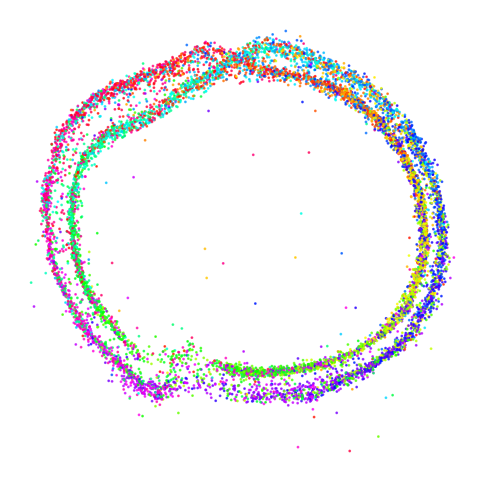

In [6]:
plt.figure(figsize=(6,6))
plt.scatter(private[:, 0], private[:, 1], c=angles_test[:], s=1, cmap='hsv', alpha=0.7);
plt.axis("off")
# plt.xlim(-13,8); plt.ylim(-13,8)
# plt.savefig("../figures/isomap_splice_mnist_z_b.png", transparent=True, dpi=300)

(array([7080., 7008., 7042., 6902., 6953., 7005., 6916., 7022., 6992.,
        7080.]),
 array([1.65787095e-03, 3.60011864e+01, 7.20007172e+01, 1.08000244e+02,
        1.43999771e+02, 1.79999298e+02, 2.15998825e+02, 2.51998367e+02,
        2.87997894e+02, 3.23997406e+02, 3.59996948e+02]),
 <BarContainer object of 10 artists>)

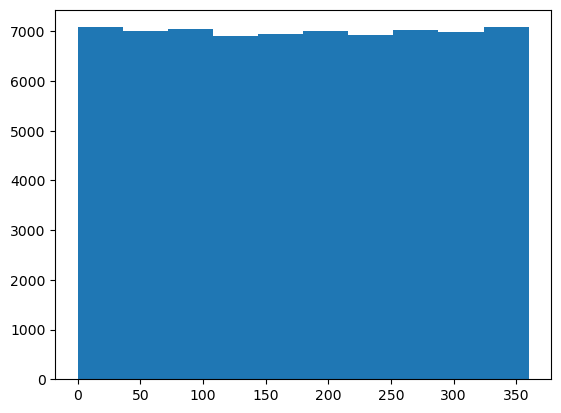

In [18]:
plt.hist(data["angles"])

In [19]:
dims = [2,3,5,7,10]
n_shared = 30
n_privateA = 0

top2_var = np.zeros(5)

for dim in dims:
    print("dim: ", dim)
     
    first_layer = 30 + dim 
    layers_msr = [first_layer,64,128,256]

    model = SPLICE(
        784,
        784,
        n_shared=n_shared,
        n_private_a=n_privateA,
        n_private_b=dim,
        enc_layers=[256, 128, 64, first_layer],
        dec_layers=[first_layer, 64, 128, 256],
        msr_layers=layers_msr 
    ).to(device)

    try:
        print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_mnist_%dD.pt" % dim)))
    except:
        pass

    private = model.F_b(Y_test).detach().cpu().numpy()

    pca = PCA(n_components=dim)
    pca.fit(private)

    # plt.figure()
    # plt.plot(np.arange(dim)+1, np.cumsum(pca.explained_variance_ratio_), marker='o')
    # plt.xlim(0, 10); plt.ylim(0, 1)

    # print(np.cumsum(pca.explained_variance_ratio_)[1])
    # print(dims.index(dim))

    top2_var[dims.index(dim)] = np.cumsum(pca.explained_variance_ratio_)[1]

dim:  2
<All keys matched successfully>
dim:  3
<All keys matched successfully>
dim:  5
<All keys matched successfully>
dim:  7
<All keys matched successfully>
dim:  10
<All keys matched successfully>


(0.0, 1.1)

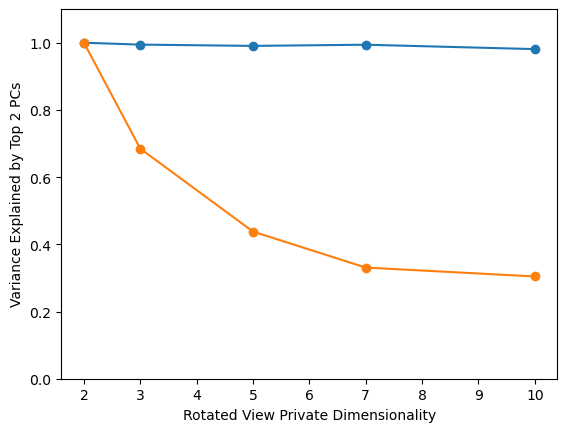

In [20]:
plt.plot(dims, top2_var, marker='o');

dmvae_top2_var = [1.        , 0.68459785, 0.43790761, 0.33081329, 0.30434042]
plt.plot(dims, dmvae_top2_var, marker='o');
# plt.title("SPLICE MNIST Private Variance Explained by Top 2 PCs")
plt.ylabel('Variance Explained by Top 2 PCs')
plt.xlabel('Rotated View Private Dimensionality')

plt.ylim(0, 1.1)

# plt.savefig("../figures/jmlr/SPLICE_MNIST_extra_dims_top2pc.svg", transparent=True, dpi=300)

### Cross reconstructions

In [6]:
def rot_digit(m, angle=-1):
    """
    Returns the digit/image "m" by a random angle [-45,45]deg
    clips it to MNIST size
    and returns it flattened into (28*28,) shape
    """
    if angle < 0:
        angle=np.random.rand()*360 #will lead to ambiguities because "6" = "9"

    m = m.reshape((28,28))
    tmp = rotate(m, angle=angle)
    xs, ys = tmp.shape
    xs = int(xs/2)
    ys = int(ys/2)
    rot_m = tmp[xs-14:xs+14,ys-14:ys+14]
    return rot_m.reshape((28*28,)), angle

In [7]:
dims = [2,3,5,7,10]
n_shared = 30
n_privateA = 0
wseed = 0

top2_var = np.zeros(5)

#digit and angle sources
digit_source = torch.Tensor(np.tile(data["original"][-10000:][2463].reshape(-1,784), [5,1])).to(device)
rot_angles = [36, 108, 180, 252, 324]
rot_inds = [264, 3910, 2463, 4756, 7293]
angle_sources = np.zeros((5,784))

for i, angle in enumerate(rot_angles):
    angle_sources[i] = rot_digit(data["original"][-10000:][rot_inds[i]], angle=angle)[0]
angle_sources = torch.Tensor(angle_sources).reshape(-1,784).to(device)


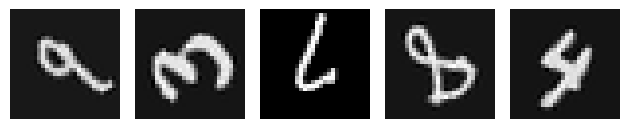

In [8]:
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(angle_sources[i].detach().cpu().numpy().squeeze().reshape(28, 28), cmap="gray")
    # plt.savefig(f"../../figures/arxiv_figures/Lee_cross_rec_{i}.png", transparent=True, dpi=300)
    plt.axis("off");

plt.tight_layout()


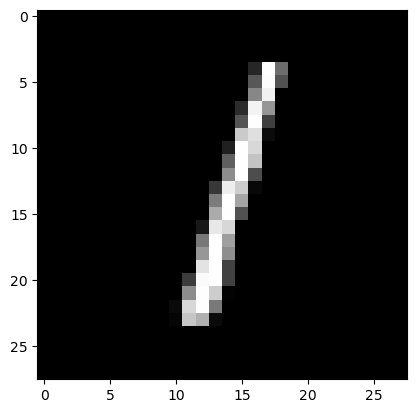

In [89]:
plt.imshow(data["original"][-10000:][2].reshape(28,28), cmap="gray")

dim:  2
<All keys matched successfully>
dim:  3
<All keys matched successfully>
dim:  5
<All keys matched successfully>
dim:  7
<All keys matched successfully>
dim:  10
<All keys matched successfully>


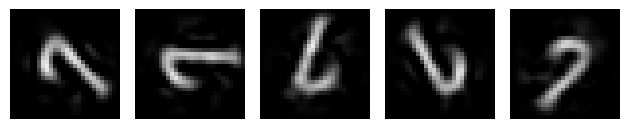

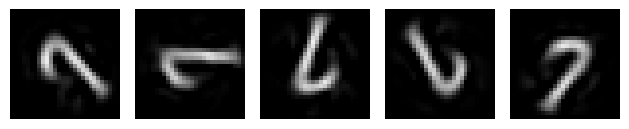

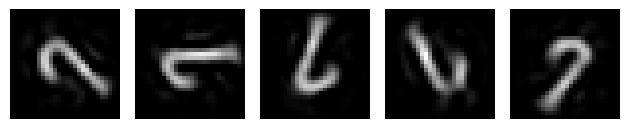

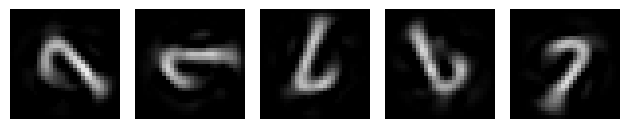

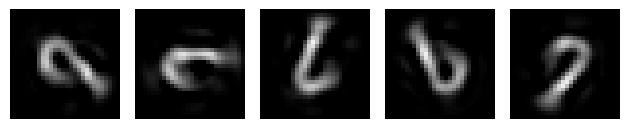

In [9]:
for dim in dims:
    print("dim: ", dim)

    first_layer = 30 + dim
    layers_msr = [first_layer,64,128,256]

    model = SPLICE(
        784,
        784,
        n_shared=n_shared,
        n_private_a=n_privateA,
        n_private_b=dim,
        layers_enc=[256, 128, 64, first_layer],
        layers_dec=[first_layer, 64, 128, 256], 
        layers_msr=layers_msr,
    ).to(device)

    try:
        print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_mnist_%dD.pt" % dim)))
    except:
        continue

    shared_cross = model.F_a2b(digit_source)
    private_cross = model.F_b(angle_sources)

    cross_rec = model.G_b(torch.cat((private_cross, shared_cross), dim=-1))

    plt.figure()
    for i in range(5):
        plt.subplot(1, 5, i+1)
        plt.imshow(cross_rec[i].detach().cpu().numpy().squeeze().reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        plt.axis("off");

    plt.tight_layout()
    # plt.savefig("../figures/jmlr/SPLICE_%ddim_cross_rec.svg" % (dim), transparent=True, dpi=300)



### SVM for digit identity on privates

In [27]:
Y.shape

torch.Size([50000, 1, 28, 28])

In [29]:
dims = [2,3,5,7,10]
private_svm_acc = np.zeros(5)
chance_svm_acc = np.zeros((5,500))

for dim in dims:
    print("dim: ", dim)
    if dim == 2:
        layers_msr = [32,32,64,128,256]
    else:
        layers_msr = [32,64,128,256]

    model = SPLICE(
        784,
        784,
        n_shared=n_shared,
        n_priv_a=n_privateA,
        n_priv_b=dim,
        layers_enc=[256, 128, 64, 32],
        layers_dec=[32, 64, 128, 256],
        layers_msr=layers_msr,
    ).to(device)

    print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_isomap_mnist_%dD.pt" % dim)))

    private = model.F_b(Y).detach().cpu().numpy()
    
    private_test = model.F_b(Y_test).detach().cpu().numpy()
    
    svm = LinearSVC(max_iter=10000)
    svm.fit(private[:20000], data["labels"][:20000].astype(int))
    private_svm_acc[dims.index(dim)] = svm.score(private_test, data["labels"][60000:].astype(int))

    # permutation test
    for i in range(500):
        print(i, end='\r')
        private = np.roll(private[:20000], 1, axis=0)
        private_test = np.roll(private_test, 1, axis=0)
        svm.fit(private, data["labels"][:20000].astype(int))
        chance_svm_acc[dims.index(dim),i] = svm.score(private_test, data["labels"][60000:].astype(int))


dim:  2
<All keys matched successfully>


c:\Users\Harris_Lab\miniconda3\envs\splice\Lib\site-packages\sklearn\svm\_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


KeyboardInterrupt: 

In [26]:
private_svm_acc

array([0.1116, 0.1158, 0.1198, 0.1316, 0.1401])

In [28]:
private_svm_pvals = np.zeros(5)
for i in range(5):
    private_svm_pvals[i] = (np.sum(private_svm_acc[i] < chance_svm_acc[i])) / 500

private_svm_pvals

array([0.852, 0.008, 0.   , 0.   , 0.   ])

### theta-related variance in privates

In [11]:
n_shared = 30
n_privateA = 0

In [12]:
def rot_digit(m, angle=-1):
    """
    Returns the digit/image "m" by a random angle [-45,45]deg
    clips it to MNIST size
    and returns it flattened into (28*28,) shape
    """
    if angle < 0:
        angle=np.random.rand()*360 #will lead to ambiguities because "6" = "9"

    m = m.reshape((28,28))
    tmp = rotate(m, angle=angle)
    xs, ys = tmp.shape
    xs = int(xs/2)
    ys = int(ys/2)
    rot_m = tmp[xs-14:xs+14,ys-14:ys+14]
    return rot_m.reshape((28*28,)), angle

In [13]:
def find_offset(digit, reference, model):
    rot = np.zeros((360, 28*28))

    for i in range(360):
        rot[i] = rot_digit(digit, angle=i)[0]

    rot = torch.Tensor(rot).to(device)
    rot[rot > 1] = 1
    rot[rot < 0] = 0

    # z_y = model.target_enc(rot).detach().cpu().numpy().squeeze()
    z_y = model.F_b(rot).detach().cpu().numpy()

    coarse_shift = np.arange(0, 360, 20)
    inner_prods = np.zeros_like(coarse_shift)

    for i, shift in enumerate(coarse_shift):
        shifted = np.roll(z_y[:,0], shift)
        inner_prods[i] = np.dot(shifted-18, reference-18)

    best_coarse = coarse_shift[np.argmax(inner_prods)]

    fine_shift = np.arange(best_coarse-10, best_coarse+10)
    inner_prods = np.zeros_like(fine_shift)

    for i, shift in enumerate(fine_shift):
        shifted = np.roll(z_y[:,0], shift)
        inner_prods[i] = np.dot(shifted-18, reference-18)

    best_fine = fine_shift[np.argmax(inner_prods)]

    return best_fine
    

In [14]:
base_rot = np.zeros((360, 28*28))
for i in range(360):
    base_rot[i] = rot_digit(X_test[-10000:][0].detach().cpu().numpy(), angle=i)[0]

base_rot = torch.Tensor(base_rot).to(device)

base_rot[base_rot > 1] = 1
base_rot[base_rot < 0] = 0

z_y = model.F_b(base_rot).detach().cpu().numpy()

In [ ]:
dims = [2,3,5,7,10]
# shifts = np.load(r"C:\Users\Harris_Lab\Projects\SPLICE\results\mnist_test5k_shifts.npy")
var_explained_by_theta = np.zeros(5)
dim = 2

# for dim in dims:
for id in range(1):
    print("dim: ", id)
    model = SPLICE(
        784,
        784,
        n_shared=n_shared,
        n_private_a=n_privateA,
        n_private_b=dim,
        enc_layers=[256, 128, 64, 30 + dim],
        dec_layers=[30 + dim, 64, 128, 256] ,
        msr_layers=[30 + dim, 64, 128, 256],
    ).to(device)

    print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_isomap_mnist_2D_lgeo0.001.pt")))

    private_test = model.F_b(Y_test).detach().cpu().numpy()

    shifts = np.zeros(5000)

    for i in range(5000):
        print(i, end="\r")
        shifts[i] = find_offset(X_test[-10000:][i].detach().cpu().numpy(), z_y[:,0], model) 

    window_vars = []
    shifted_angles = (data["angles"][-10000:][:5000]+shifts) % 360
    full_var = np.var(private_test[:5000], axis=0)
    width = 0.5

    for i in range(360):
        window = private_test[:5000][(shifted_angles > i) & (shifted_angles < i+width)]
        var = np.var(window, axis=0)/full_var
        window_vars.append(np.nanmean(var))
    var_explained_by_theta[id] = 1 - np.nanmean(window_vars)
    print(var_explained_by_theta[id])
    

dim:  0
<All keys matched successfully>
0.9789407141506672


c:\Users\Harris_Lab\miniconda3\envs\splice\Lib\site-packages\numpy\core\fromnumeric.py:3787: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\Harris_Lab\miniconda3\envs\splice\Lib\site-packages\numpy\core\_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\Harris_Lab\miniconda3\envs\splice\Lib\site-packages\numpy\core\_methods.py:195: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
C:\Users\Harris_Lab\AppData\Local\Temp\ipykernel_28176\3629536639.py:38: RuntimeWarning: Mean of empty slice
  window_vars.append(np.nanmean(var))


In [133]:
full_var

array([43.89222 , 26.630545], dtype=float32)

In [130]:
1 - np.nanmean(window_vars)

0.9695982858538628

In [140]:
DMVAE_var_explained_by_theta = np.array([0.76140574, 0.72264689, 0.55791992, 0.42863166, 0.36137307])

In [86]:
var_explained_by_theta

array([       nan, 0.31197178, 0.28800267,        nan, 0.        ])

(0.0, 1.0)

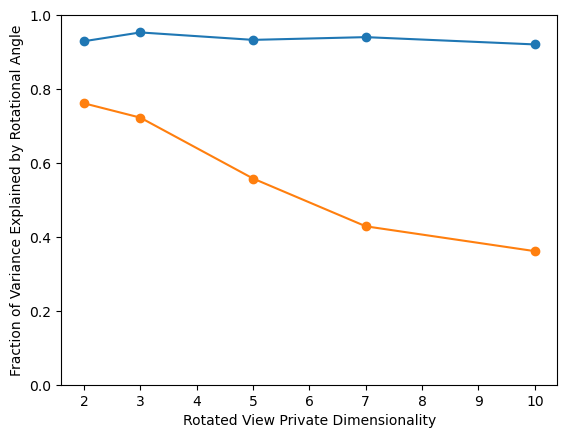

In [142]:
# USE THIS ONE

plt.plot(dims, var_explained_by_theta, marker='o', label="SPLICE");
plt.plot(dims, DMVAE_var_explained_by_theta, marker='o', label="DMVAE");
# plt.title("SPLICE MNIST Private Variance Explained by Rotational Angle")
plt.ylabel("Fraction of Variance Explained by Rotational Angle")
plt.xlabel('Rotated View Private Dimensionality')

# plt.legend()
plt.ylim(0, 1.0)

# plt.savefig("../figures/jmlr/SPLICE_MNIST_extra_dims_theta-var-exp.svg", transparent=True, dpi=300)

In [150]:
dim=2
n_shared=30
layers_msr = [32,64,128,256]
model = SPLICE(
    784,
    784,
    n_shared=n_shared,
    n_private_a=0,
    n_private_b=dim,
    enc_layers=[256, 128, 64, 32],
    dec_layers=[32, 64, 128, 256],
    msr_layers=layers_msr,
).to(device)

print(model.load_state_dict(torch.load(r"../results/models/mnist/splice_isomap_mnist_%dD.pt" % dim)))

<All keys matched successfully>


In [151]:
private = model.F_b(Y_test).detach().cpu().numpy()

In [152]:
private.shape

(10000, 2)

In [153]:
shifts = np.load(r"C:\Users\Harris_Lab\Projects\SPLICE\results\mnist_test5k_shifts.npy")

In [161]:
list((data["angles"][60000:65000]+shifts) % 360)

[138.94247436523438,
 282.9358367919922,
 306.66571044921875,
 356.44520568847656,
 97.62337493896484,
 19.766036987304688,
 178.40902709960938,
 72.10391426086426,
 104.16720581054688,
 51.70407485961914,
 46.495025634765625,
 96.24897766113281,
 114.65393829345703,
 160.24368286132812,
 308.2138366699219,
 49.63909912109375,
 237.1055908203125,
 359.8558044433594,
 76.90093994140625,
 322.418701171875,
 77.06071472167969,
 313.32486724853516,
 184.540283203125,
 19.177413940429688,
 274.42254638671875,
 340.7088928222656,
 81.6104621887207,
 9.100860595703125,
 82.93218231201172,
 312.1405029296875,
 155.15379333496094,
 232.1004180908203,
 184.2252197265625,
 13.797714233398438,
 77.83981323242188,
 70.08589172363281,
 198.6407470703125,
 316.0546875,
 226.32569885253906,
 221.93959045410156,
 253.09596252441406,
 242.16693115234375,
 299.6666564941406,
 263.08990478515625,
 184.7614288330078,
 193.91528129577637,
 214.56793212890625,
 214.47720336914062,
 243.2344512939453,
 312.49

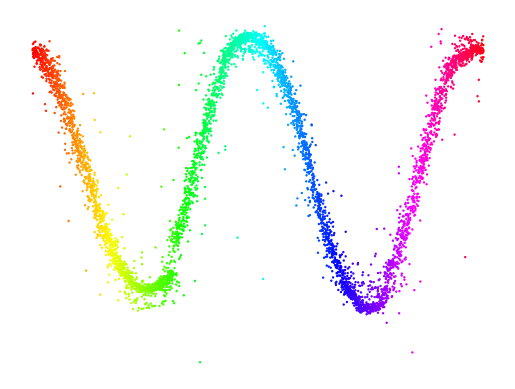

In [ ]:
plt.scatter((data["angles"][60000:65000]+shifts) % 360, private[:5000,1], s=0.5, c=list((data["angles"][60000:65000]+shifts) % 360), cmap='hsv')
plt.axis("off")
plt.savefig("../figures/arxiv_figures/splice_aligned_latent1_vs_theta.png", dpi=300, transparent=True)